In [78]:
from sklearn.model_selection import train_test_split
import numpy as np
from sklearn.datasets import make_moons
import matplotlib.pyplot as plt

epochs = 20
lr = 0.05
batch_size = 32

# 数据集准备
X, Y = make_moons(
    n_samples=1000,
    noise=0.2,
    random_state=42
)

X_train, X_temp, y_train, y_temp = train_test_split(
    X, Y,
    test_size=0.3,
    random_state=42,
    stratify=Y
)

X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp,
    test_size=0.5,
    random_state=42,
    stratify=y_temp
)

x_train_np = X_train.astype(np.float64)
y_train_np = y_train.reshape(-1, 1).astype(np.float64)

In [79]:
# 初始化参数
W1 = np.random.normal(0, 0.5, size=(2, 3))
b1 = np.zeros((1, 3))

W2 = np.random.normal(0, 0.5, size=(3, 1))
b2 = np.zeros((1, 1))

In [80]:
# 前向传播
def model_forward(x, y, W1, b1, W2, b2):
    Z1 = x @ W1 + b1
    A1 = np.maximum(0, Z1)
    Z2 = A1 @ W2 + b2
    P = 1 / (1 + np.exp(-Z2))
    L = -(y * np.log(P) + (1 - y) * np.log(1 - P))

    return Z1, A1, Z2, P, L

In [81]:
# 反向传播
def model_backward(x, y, z1, a1, p, W2):
    batch_size = x.shape[0]
    grad_p = (
        -y / p + (1 - y) / (1 - p)
    ) / batch_size
    grad_z2 = grad_p * p * (1 - p)
    grad_b2 = np.sum(grad_z2, axis=0, keepdims=True)
    grad_W2 = a1.T @ grad_z2
    grad_a1 = grad_z2 @ W2.T
    grad_z1 = grad_a1 * (z1 > 0)
    grad_b1 = np.sum(grad_z1, axis=0, keepdims=True)
    grad_W1 = x.T @ grad_z1

    return grad_W1, grad_b1, grad_W2, grad_b2

In [82]:
# 初始模型检验
_, _, _, p_test, l_test = model_forward(
    x_train_np, y_train_np,
    W1, b1, W2, b2
)

loss_test = np.mean(l_test)

predictions_test = (p_test >= 0.5).astype(int)
accuracy_test = np.mean(predictions_test == y_train_np)

print("Test Accuracy:", accuracy_test)
print("Test Loss:", loss_test)

Test Accuracy: 0.4142857142857143
Test Loss: 0.6963295902881285


In [83]:
# 模型训练手动实现
loss_history = []
acc_history = []

for epoch in range(epochs):
    indices = np.random.permutation(len(x_train_np))
    x_shuffled = x_train_np[indices]
    y_shuffled = y_train_np[indices]

    for i in range(0, len(x_train_np), batch_size):
        x_batch = x_shuffled[i:i + batch_size]
        y_batch = y_shuffled[i:i + batch_size]

        z1, a1, z2, p, l = model_forward(
            x_batch, y_batch,
            W1, b1, W2, b2
        )

        grad_W1, grad_b1, grad_W2, grad_b2 = model_backward(
            x_batch, y_batch, z1, a1, p, W2
        )

        W1 -= lr * grad_W1
        b1 -= lr * grad_b1
        W2 -= lr * grad_W2
        b2 -= lr * grad_b2

    z1, a1, z2, p, l = model_forward(
        x_train_np, y_train_np,
        W1, b1, W2, b2
    )

    loss = np.mean(l)

    predictions = (p >= 0.5).astype(int)
    accuracy = np.mean(predictions == y_train_np)

    loss_history.append(loss)
    acc_history.append(accuracy)

    print("Epoch:", epoch + 1)
    print("Accuracy:", acc_history[epoch],"Loss:", loss_history[epoch])

Epoch: 1
Accuracy: 0.7628571428571429 Loss: 0.6527529556093011
Epoch: 2
Accuracy: 0.7428571428571429 Loss: 0.6227875020933532
Epoch: 3
Accuracy: 0.7557142857142857 Loss: 0.5947366514391328
Epoch: 4
Accuracy: 0.7642857142857142 Loss: 0.5645808064030395
Epoch: 5
Accuracy: 0.7771428571428571 Loss: 0.5329373495806011
Epoch: 6
Accuracy: 0.78 Loss: 0.5013100779635598
Epoch: 7
Accuracy: 0.7871428571428571 Loss: 0.47124713969822274
Epoch: 8
Accuracy: 0.7985714285714286 Loss: 0.4449195157699033
Epoch: 9
Accuracy: 0.8042857142857143 Loss: 0.4226404037428423
Epoch: 10
Accuracy: 0.81 Loss: 0.4041647835669242
Epoch: 11
Accuracy: 0.8142857142857143 Loss: 0.38915816157588257
Epoch: 12
Accuracy: 0.8185714285714286 Loss: 0.3767453199690361
Epoch: 13
Accuracy: 0.8271428571428572 Loss: 0.36637650129797295
Epoch: 14
Accuracy: 0.8328571428571429 Loss: 0.3573286861201546
Epoch: 15
Accuracy: 0.8357142857142857 Loss: 0.3494724485063321
Epoch: 16
Accuracy: 0.84 Loss: 0.3426448598272917
Epoch: 17
Accuracy: 0.84

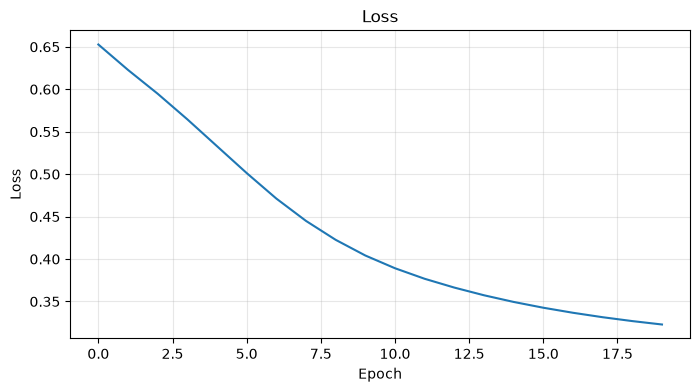

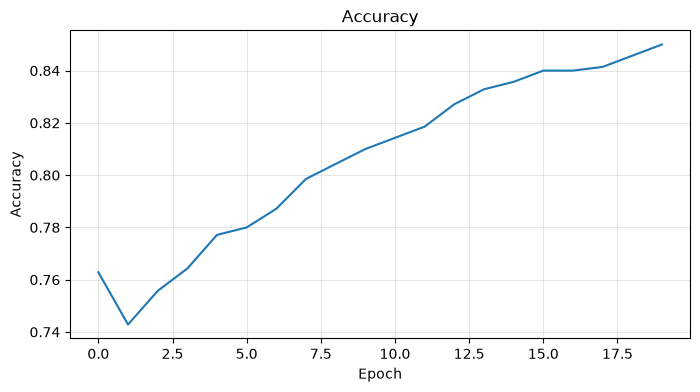

In [84]:
# 绘制曲线
plt.figure(figsize=(8, 4))
plt.plot(loss_history)
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Loss")
plt.grid(alpha=0.3)
plt.show()

plt.figure(figsize=(8, 4))
plt.plot(acc_history)
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Accuracy")
plt.grid(alpha=0.3)
plt.show()

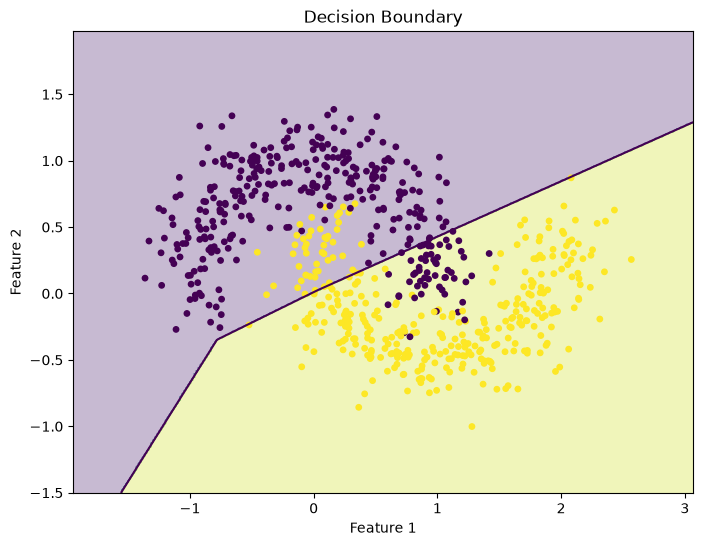

In [85]:
# 二维决策边界
x_min, x_max = X[:, 0].min() - 0.5, X[:, 0].max() + 0.5
y_min, y_max = X[:, 1].min() - 0.5, X[:, 1].max() + 0.5

xx, yy = np.meshgrid(
    np.linspace(x_min, x_max, 300),
    np.linspace(y_min, y_max, 300)
)

grid = np.c_[xx.ravel(), yy.ravel()]

z1_grid = grid @ W1 + b1
a1_grid = np.maximum(0, z1_grid)
z2_grid = a1_grid @ W2 + b2
p_grid = 1 / (1 + np.exp(-z2_grid))

p_grid = p_grid.reshape(xx.shape)

plt.figure(figsize=(8, 6))

plt.contourf(
    xx, yy,
    (p_grid >= 0.5).astype(int),
    alpha=0.3
)

plt.contour(
    xx, yy, p_grid,
    levels=[0.5]
)

plt.scatter(
    x_train_np[:, 0],
    x_train_np[:, 1],
    c=y_train_np.ravel(),
    s=15
)

plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.title("Decision Boundary")
plt.show()

# 实现了简易模型训练，在训练集上准确率能够逐步上升，loss能够逐步下降，模型能一定程度上实现分类。但决策边界体现为笔直的折线，因为模型结构简单，拟合能力有限